# Mini-projet Séries Temporelles — Partie 3 : VAR, causalité de Granger, cointégration, VECM (section 3.2)
Prérequis : `01_eda.ipynb` (jeu de données) ; `02_sarima.ipynb` (pour le tableau de prévisions commun).

**Paire de variables** : `log(core)` (production, I(1)) et `t_max_mean` (température maximale moyenne mensuelle). Deux points de méthode, hérités de l'EDA et fixés **avant** de regarder les résultats :
1. La température n'est pas I(1) : elle est stationnaire autour d'une tendance (réchauffement) et d'un profil saisonnier. Le VAR est donc estimé **en niveaux, avec termes déterministes** (dummies mensuelles + tendance linéaire + indicatrice COVID), et la causalité de Granger est testée par la méthode de **Toda-Yamamoto** (un retard supplémentaire), valide même quand les variables sont de natures différentes (I(1) et I(0)).
2. La cointégration de Johansen suppose des variables I(1) : on la teste comme demandé, mais on s'attend à devoir **interpréter prudemment** un éventuel résultat positif.

In [1]:
import warnings, platform, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels, statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen, VECM
from common import load, split, metrics, save_forecasts

warnings.filterwarnings("ignore")
SEED = 42; random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
print("python", platform.python_version(), "| statsmodels", statsmodels.__version__)

df = load(); df["ly"] = np.log(df["core"]); train, test = split(df)
T = "t_max_mean"
clim = train[["ly", T]].groupby(train.index.month).mean()          # profil saisonnier estimé sur le TRAIN uniquement

python 3.12.3 | statsmodels 0.15.0


## 1. Rappel de stationnarité de la paire (séries désaisonnalisées par la moyenne mensuelle)

In [2]:
des = lambda s: s - clim[s.name].loc[s.index.month].values       # retire la moyenne mensuelle
rows = []
for name, s in [("log(core)", des(train["ly"])), (T, des(train[T]))]:
    for reg, lab in [("c", "const."), ("ct", "const.+tend.")]:
        a, k = adfuller(s, regression=reg, autolag="AIC"), kpss(s, regression=reg, nlags="auto")
        rows.append({"série": name, "spec": lab, "ADF p": a[1], "KPSS p": k[1]})
    a, k = adfuller(s.diff().dropna(), autolag="AIC"), kpss(s.diff().dropna(), nlags="auto")
    rows.append({"série": "Δ " + name, "spec": "const.", "ADF p": a[1], "KPSS p": k[1]})
display(pd.DataFrame(rows).set_index(["série", "spec"]).round(3))
sl = np.polyfit(np.arange(len(train)) / 12, des(train[T]), 1)[0]
print(f"pente de la température max désaisonnalisée : {sl:+.3f} °C par an  (≈ {sl*len(train)/12:+.1f} °C sur la période d'apprentissage)")

ADF p  KPSS p
série        spec                       
log(core)    const.        0.202   0.010
             const.+tend.  0.990   0.010
Δ log(core)  const.        0.000   0.100
t_max_mean   const.        0.787   0.010
             const.+tend.  0.000   0.073
Δ t_max_mean const.        0.000   0.100

pente de la température max désaisonnalisée : +0.137 °C par an  (≈ +2.4 °C sur la période d'apprentissage)


**Lecture.** `log(core)` est non stationnaire quelle que soit la spécification (KPSS rejette ; ADF ne rejette pas) et sa différence première est stationnaire : I(1). La température max désaisonnalisée est **stationnaire autour d'une tendance** (avec tendance : ADF rejette, p < 0,001, KPSS ne rejette pas, p = 0,073 ; avec constante seule, les tests ne concluent pas, car la tendance les perturbe). *Nuance* : le verdict KPSS avec tendance est limite et dépend de la fenêtre de calcul (p = 0,073 ici, ≈ 0,03 avec la fenêtre longue utilisée dans le script R) ; c'est l'ADF avec tendance, nettement rejetée dans les deux langages, qui porte la conclusion. Cette tendance est un **réchauffement de ≈ +0,14 °C par an (≈ +2,4 °C sur la période d'apprentissage)** dans cette série de réanalyse (valeur à vérifier avec une station avant de la citer comme fait climatique). On a donc **une variable I(1) et une variable stationnaire autour d'une tendance** : exactement le cas où un test de cointégration standard est fragile.

## 2. VAR en niveaux : choix de l'ordre, estimation, diagnostic
Variables ordonnées `[température, log production]` (la météo ne réagit pas à la production dans le mois : ordre utilisé pour les fonctions de réponse). Termes déterministes : 11 dummies mensuelles, tendance linéaire, indicatrice COVID.

In [3]:
def exog(idx, offset=0):
    M = pd.DataFrame({f"m{i}": (idx.month == i).astype(float) for i in range(2, 13)}, index=idx)
    M["trend"] = (np.arange(len(idx)) + offset) / 12
    M["covid_2020_04"] = df.loc[idx, "covid_2020_04"].values
    return M

Y = train[[T, "ly"]].copy(); EX = exog(train.index)
mod = VAR(Y, exog=EX)
sel = mod.select_order(maxlags=12)
ic = pd.DataFrame({k: [mod.fit(p).info_criteria[k] for p in range(1, 9)] for k in ["aic", "bic", "hqic", "fpe"]}, index=range(1, 9))
ic["Portmanteau p (retards p+24)"] = [mod.fit(p).test_whiteness(nlags=p + 24).pvalue for p in range(1, 9)]
ic.index.name = "p"; display(ic.round(4)); print("ordre minimisant AIC / BIC / HQIC :", sel.selected_orders["aic"], "/", sel.selected_orders["bic"], "/", sel.selected_orders["hqic"])

,aic,bic,hqic,fpe,Portmanteau p (retards p+24)
p,,,,,
1,-5.9351,-5.4268,-5.7296,0.0026,0.0295
2,-5.9580,-5.3842,-5.7261,0.0026,0.1061
3,-5.9305,-5.2908,-5.6719,0.0027,0.1832
4,-5.9375,-5.2315,-5.6520,0.0026,0.2923
5,-6.0118,-5.2390,-5.6993,0.0025,0.4145
6,-5.9928,-5.1528,-5.6531,0.0025,0.4114
7,-6.0045,-5.0968,-5.6374,0.0025,0.3895
8,-6.0010,-5.0251,-5.6063,0.0025,0.3792


ordre minimisant AIC / BIC / HQIC : 5 / 1 / 5


**Choix de l'ordre.** Les critères divergent : BIC retient 1, AIC et HQIC retiennent 5. À p = 1 le test de Portmanteau rejette l'absence d'autocorrélation résiduelle (p = 0,030) ; à **p = 2 il ne rejette plus (p = 0,106)**. On retient **p = 2**, le plus petit ordre à résidus blancs (compromis entre le BIC, trop parcimonieux ici, et l'AIC). La sensibilité au choix de p est contrôlée en section 3 (p de 1 à 6).

In [4]:
P = 2                                                    # voir interprétation : plus petit ordre à résidus blancs
var = mod.fit(P)
print("stable (racines hors du cercle unité) :", var.is_stable(), "| module max des racines inverses :", round(max(abs(1 / var.roots)) if len(var.roots) else np.nan, 3))
names = list(Y.columns)
eq = pd.DataFrame({"effet sur " + names[i]: [var.coefs[l][i, j] for l in range(P) for j in range(2)] for i in range(2)},
                  index=pd.MultiIndex.from_product([[f"retard {l+1}" for l in range(P)], names]))
display(eq.round(4))
pw = var.test_whiteness(nlags=P + 24); nm = var.test_normality()
print(f"Portmanteau (autocorrélation résiduelle) : p = {pw.pvalue:.3f} | normalité conjointe (Jarque-Bera) : p = {nm.pvalue:.4f}")
print("corrélation des résidus (instantanée) :", round(var.resid.corr().iloc[0, 1], 3))

stable (racines hors du cercle unité) : True | module max des racines inverses : 0.784


effet sur t_max_mean  effet sur ly
retard 1 t_max_mean                0.2438       -0.0043
         ly                        0.1553        0.5120
retard 2 t_max_mean                0.0201       -0.0019
         ly                       -3.0915        0.1754

Portmanteau (autocorrélation résiduelle) : p = 0.106 | normalité conjointe (Jarque-Bera) : p = 0.7064
corrélation des résidus (instantanée) : 0.309


**Diagnostic du VAR(2).** Stable (module maximal des racines inverses 0,78 < 1), résidus sans autocorrélation (Portmanteau p = 0,106) et compatibles avec la normalité conjointe (Jarque-Bera p = 0,71). Les résidus des deux équations sont corrélés à **0,31** : une partie du lien température/production se produit **dans le même mois**, ce que les coefficients retardés ne peuvent pas montrer. Les effets retardés de la température sur la production sont minuscules (≈ −0,004 puis −0,002 en log) ; ceux de la production sur la température ne sont pas interprétables isolément (production en log, température en °C) et sont testés proprement ci-dessous.

## 3. Causalité de Granger (Toda-Yamamoto) et causalité instantanée
Pour un VAR(p) en niveaux, on estime un VAR(p+1) et on teste par un Wald χ² la nullité des **p premiers** retards de l'autre variable (le retard supplémentaire absorbe la non-stationnarité). Robustesse : p de 1 à 6.

In [5]:
def toda_yamamoto(dep, cause, p, dmax=1):
    d = pd.DataFrame(index=Y.index)
    for l in range(1, p + dmax + 1):
        for c in Y.columns: d[f"{c}_l{l}"] = Y[c].shift(l)
    X = pd.concat([d, EX], axis=1).dropna(); y = Y[dep].loc[X.index]
    r = sm.OLS(y, sm.add_constant(X)).fit()
    R = np.zeros((p, len(r.params)))
    for i in range(p): R[i, list(r.params.index).index(f"{cause}_l{i+1}")] = 1
    w = r.wald_test(R, use_f=False, scalar=True); return float(w.statistic), float(w.pvalue)

rows = []
for p in range(1, 7):
    s1, p1 = toda_yamamoto("ly", T, p); s2, p2 = toda_yamamoto(T, "ly", p)
    rows.append({"p": p, "température → production : χ²": s1, "p-value": p1, "production → température : χ²": s2, "p-value ": p2})
display(pd.DataFrame(rows).set_index("p").round(3))

inst = var.test_inst_causality(causing=[T])
print(f"Causalité instantanée température ↔ production (VAR({P})) : stat = {inst.test_statistic:.1f}, p = {inst.pvalue:.2g}")

,température → production : χ²,p-value,production → température : χ²,p-value
p,,,,
1,3.138,0.076,0.005,0.943
2,3.821,0.148,0.661,0.719
3,3.777,0.287,1.352,0.717
4,2.632,0.621,7.941,0.094
5,7.973,0.158,6.621,0.250
6,8.601,0.197,5.755,0.451


Causalité instantanée température ↔ production (VAR(2)) : stat = 18.3, p = 1.9e-05


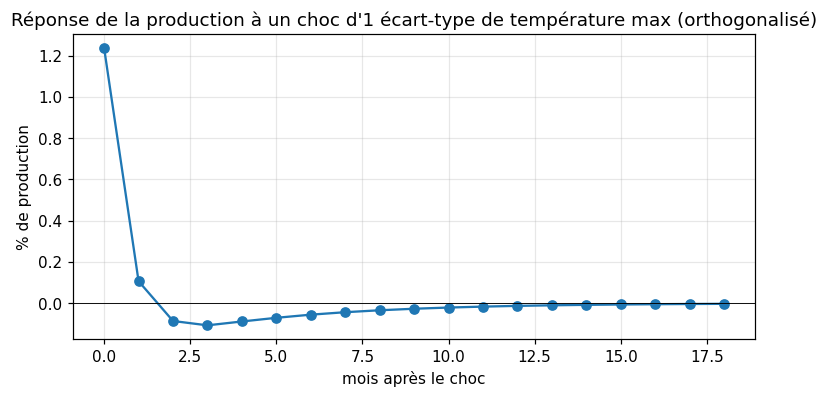

écart-type du choc de température : 1.23 °C | réponse cumulée à 12 mois : 0.78 %
réponses aux horizons 0..4 (%) : [ 1.24  0.11 -0.09 -0.11 -0.09]


In [6]:
# Fonction de réponse : choc d'1 écart-type de température -> réponse de log(production), en %
irf = var.irf(18)
resp = irf.orth_irfs[:, 1, 0] * 100                       # [horizon, réponse=ly, impulsion=T]
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.plot(range(19), resp, marker="o"); ax.axhline(0, color="k", lw=.6)
ax.set_xlabel("mois après le choc"); ax.set_ylabel("% de production"); ax.set_title("Réponse de la production à un choc d'1 écart-type de température max (orthogonalisé)")
plt.show()
print("écart-type du choc de température :", round(np.sqrt(var.sigma_u.iloc[0, 0]), 2), "°C | réponse cumulée à 12 mois :", round(resp[:13].sum(), 2), "%")
print("réponses aux horizons 0..4 (%) :", resp[:5].round(2))

**Causalité de Granger (Toda-Yamamoto).**
- **Température → production** : aucune significativité à 5 % pour aucun p de 1 à 6 (p-values de 0,076 à 0,621). Les valeurs *passées* de la température n'apportent pas d'information prédictive supplémentaire sur la production, une fois prises en compte la saisonnalité, la tendance et le passé de la production.
- **Production → température** : aucune significativité non plus (p-values de 0,094 à 0,943), ce qui est cohérent avec la physique (la production d'électricité n'influence pas la météo) ; c'est un test de plausibilité réussi.
- **Causalité instantanée** : forte (χ² = 18,3, p = 1,9·10⁻⁵, corrélation résiduelle 0,31). La relation est **contemporaine** : la chaleur du mois agit sur la production *du même mois*.
- **Fonction de réponse** (ordre : température d'abord) : un choc d'1 écart-type de température (≈ 1,2 °C) augmente la production d'environ **+1,2 % le même mois**, puis l'effet disparaît (≈ ±0,1 % ensuite ; cumul à 12 mois ≈ 0,8 %). L'effet est immédiat et transitoire, ce qui correspond à une demande de climatisation qui suit la température au jour le jour.
- **Limite** : un VAR linéaire traite pareil +1 °C en janvier et en juillet ; les résultats de la section 3.1 (SARIMAX) suggèrent que l'intensité de la chaleur (degrés-jours) compte davantage que la température moyenne. L'absence de Granger ne veut donc **pas** dire « la température n'influence pas la production » : elle dit que son influence passe par le mois courant, pas par ses retards.

## 4. Cointégration
Séries désaisonnalisées (moyenne mensuelle du train retirée). **Johansen** : trace et max-eigenvalue, plusieurs spécifications déterministes et retards (robustesse) ; **Engle-Granger** : pour la paire.

In [7]:
D = pd.DataFrame({"ly": des(train["ly"]), T: des(train[T])})
def rank(j, which="trace"):
    stat, cv = (j.lr1, j.cvt[:, 1]) if which == "trace" else (j.lr2, j.cvm[:, 1])
    r = 0
    while r < len(stat) and stat[r] > cv[r]: r += 1
    return r
rows = []
for det, lab in [(-1, "aucun"), (0, "constante"), (1, "tendance")]:
    for k in (1, 2, 3, 6):
        j = coint_johansen(D, det_order=det, k_ar_diff=k)
        rows.append({"déterministe": lab, "k (retards ΔX)": k, "trace r=0": j.lr1[0], "vc 95 %": j.cvt[0, 1], "trace r≤1": j.lr1[1], "vc95 % ": j.cvt[1, 1],
                     "rang (trace)": rank(j), "rang (max-vp)": rank(j, "max")})
jt = pd.DataFrame(rows); display(jt.round(1))
eg = {t: coint(D["ly"], D[T], trend=t)[1] for t in ("c", "ct")}; eg2 = {t: coint(D[T], D["ly"], trend=t)[1] for t in ("c", "ct")}
print("Engle-Granger p-values  ly ~ T :", {k: round(v, 3) for k, v in eg.items()}, "| T ~ ly :", {k: round(v, 3) for k, v in eg2.items()})
sub = D.loc[:"2019-12"]; js = coint_johansen(sub, det_order=0, k_ar_diff=1)
print("Johansen sous-période 2005-2019 (const., k=1) : trace =", js.lr1.round(1), "vc95 =", js.cvt[:, 1].round(1), "-> rang", rank(js))

,déterministe,k (retards ΔX),trace r=0,vc 95 %,trace r≤1,vc95 %,rang (trace),rang (max-vp)
0,aucun,1,63.0,12.3,2.5,4.1,1,1
1,aucun,2,48.1,12.3,2.2,4.1,1,1
2,aucun,3,42.7,12.3,1.8,4.1,1,1
3,aucun,6,25.5,12.3,3.1,4.1,1,1
4,constante,1,62.9,15.5,2.5,3.8,1,1
5,constante,2,48.1,15.5,2.2,3.8,1,1
6,constante,3,42.6,15.5,1.8,3.8,1,1
7,constante,6,25.8,15.5,3.5,3.8,1,1
8,tendance,1,93.5,18.4,21.1,3.8,2,2
9,tendance,2,76.9,18.4,16.3,3.8,2,2


Engle-Granger p-values  ly ~ T : {'c': 0.58, 'ct': 0.971} | T ~ ly : {'c': 0.0, 'ct': 0.0}
Johansen sous-période 2005-2019 (const., k=1) : trace = [57.   1.9] vc95 = [15.5  3.8] -> rang 1


**Cointégration : résultats à interpréter avec prudence.**
- **Johansen** : rang 1 dans presque toutes les spécifications (sans déterministe ou avec constante, quel que soit k de 1 à 6 ; aussi sur 2005-2019). Avec tendance linéaire autorisée, le rang est 2 pour k = 1 à 3 (rang plein) et 1 pour k = 6.
- **Engle-Granger** : *asymétrique* — `ly ~ T` ne rejette pas l'absence de cointégration (p = 0,58 et 0,97), alors que `T ~ ly` la rejette (p ≈ 0). Une telle asymétrie est compatible avec une variable déjà stationnaire (ici la température) : le résidu est stationnaire parce que `T` l'est, pas parce qu'une relation d'équilibre existe. (Le test alternatif de Phillips-Ouliaris, exécuté dans le script R, rejette dans les deux ordres : les tests de cointégration par paire ne sont pas fiables pour ce couple de variables, ce qui incite à ne pas s'appuyer dessus.)
- **Conclusion provisoire** : le « rang 1 » de Johansen ne peut pas être lu comme un équilibre de long terme entre production et température. Le test suppose des variables I(1) ; ici l'une est stationnaire autour d'une tendance de réchauffement et l'autre est I(1), et les deux montent sur la période. La section 5 examine qui s'ajuste réellement.

## 5. VECM (rang 1 retenu par le test de Johansen) et lecture du terme de correction d'erreur

In [8]:
vecm = VECM(D, k_ar_diff=1, coint_rank=1, deterministic="co").fit()
beta = vecm.beta.ravel(); alpha = vecm.alpha.ravel(); pa = vecm.pvalues_alpha.ravel()
print(f"vecteur de cointégration (normalisé sur log core) : β = (1 ; {beta[1]:+.3f})  -> ECT = ly {beta[1]:+.3f}·T")
print(pd.DataFrame({"α (vitesse d'ajustement)": alpha, "p-value": pa}, index=["Δ log core", "Δ température"]).round(4))
print("demi-vie implicite de l'ajustement de la température :", round(np.log(.5) / np.log(1 + alpha[1] * beta[1]), 1), "mois" if (1 + alpha[1] * beta[1]) < 1 else "(non défini)")

vecteur de cointégration (normalisé sur log core) : β = (1 ; -0.277)  -> ECT = ly -0.277·T
               α (vitesse d'ajustement)  p-value
Δ log core                       0.0212   0.0548
Δ température                    2.5430   0.0000
demi-vie implicite de l'ajustement de la température : 0.6 mois


**Lecture du VECM.** Le vecteur estimé est ECT = log(core) − 0,277·T. Les vitesses d'ajustement sont :
- **production** : α = +0,021 (p = 0,055) — de signe *positif* (une correction d'erreur exigerait un signe négatif) et non significative à 5 % : la production ne revient pas vers cet « équilibre » ;
- **température** : α = +2,54 (p < 0,001) : c'est la température qui « s'ajuste », avec une demi-vie d'environ 0,6 mois. Or la météo ne peut pas répondre à la production d'électricité.
- **Verdict** : ce VECM est estimé parce que l'énoncé le demande dès que Johansen détecte une cointégration, mais **il ne décrit pas un mécanisme économique ou physique**. Il reflète vraisemblablement la stationnarité de la température et/ou des tendances communes (croissance de la production, réchauffement) ; notre échantillon ne permet pas de départager ces deux lectures. Nous ne l'utilisons ni pour interpréter un équilibre de long terme ni pour prévoir. L'exemple de l'énoncé (consommation et température cointégrées) n'est donc **pas confirmé** sur nos données mensuelles : c'est un résultat négatif argumenté, pas un échec d'implémentation.

## 6. Prévisions du VAR(2) en niveaux (origine fixe fin août 2022, h = 1…24)
Les valeurs futures des termes déterministes sont connues (mois, tendance, COVID = 0) ; la température future est prévue par le VAR lui-même : **aucune information météo future n'est utilisée** (version réalisable).

,MSE,RMSE,MAE,MAPE
h=10,93798.1,306.3,281.7,20.6
h=24,98327.5,313.6,290.4,20.2


référence naïf saisonnier — RMSE h=10 / h=24 : 158.8 / 146.8


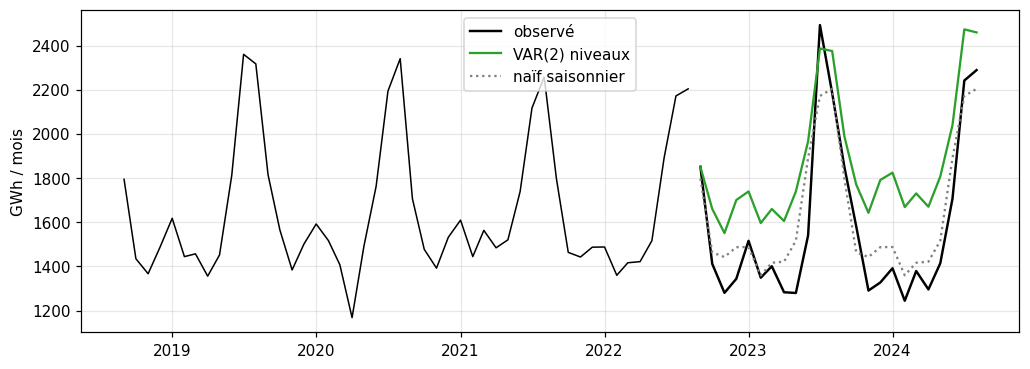

erreur relative moyenne (observé − prévu)/observé, %, par saison :
{'hors été': -25.0, 'été (juin-sept)': -9.6}


In [9]:
H = len(test); EXf = exog(test.index, offset=len(train))
fc = var.forecast(Y.values[-P:], steps=H, exog_future=EXf.values)
pred = pd.Series(np.exp(fc[:, 1]), index=test.index)
res = pd.DataFrame({h: metrics(test["core"], pred, h) for h in (10, 24)}).T; res.index = ["h=10", "h=24"]; display(res.round(1))
naif = pd.read_csv("results/forecasts.csv", index_col=0, parse_dates=True)["Naïf saisonnier"]
print("référence naïf saisonnier — RMSE h=10 / h=24 :", round(metrics(test["core"], naif, 10)["RMSE"], 1), "/", round(metrics(test["core"], naif, 24)["RMSE"], 1))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(train.index[-48:], train["core"].iloc[-48:], color="k", lw=1); ax.plot(test.index, test["core"], color="k", lw=1.6, label="observé")
ax.plot(test.index, pred, color="tab:green", label="VAR(2) niveaux"); ax.plot(test.index, naif, color="gray", ls=":", label="naïf saisonnier")
ax.legend(); ax.set_ylabel("GWh / mois"); plt.show()
print("erreur relative moyenne (observé − prévu)/observé, %, par saison :")
e = 100 * (test["core"] - pred) / test["core"]; print(e.groupby(np.where(test.index.month.isin([6, 7, 8, 9]), "été (juin-sept)", "hors été")).mean().round(1).to_dict())
save_forecasts("VAR(2) niveaux", pred); res.round(3).to_csv("results/metrics_var.csv")

**Prévision du VAR(2).** Mauvaise : RMSE de 306 (h = 10) et 314 (h = 24) GWh contre 159 et 147 pour le naïf saisonnier, MAPE ≈ 20 %. Le VAR **surestime partout**, surtout hors été (+25 % en moyenne contre +10 % l'été, en erreur relative sur l'observé). Deux causes probables, non isolées ici : la tendance linéaire déterministe prolonge la croissance de 2005-2022 alors que la production a stagné depuis 2019 ; et la saisonnalité est un profil mensuel fixe, alors que l'amplitude relative du pic d'été a évolué (EDA). Ce VAR sert à l'inférence (Granger, réponses impulsionnelles), pas à la prévision : il figure dans le tableau comparatif par transparence mais ne sera pas retenu comme modèle de prévision.

## Synthèse et suite
| Point | Conclusion |
|---|---|
| VAR(2) en niveaux (+ dummies mensuelles, tendance, COVID) | stable, résidus blancs (p = 0,106) et normaux (p = 0,71) |
| Granger (Toda-Yamamoto, p = 1 à 6) | aucune causalité retardée, dans aucun sens (toutes p > 0,05) |
| Causalité instantanée | forte (p = 2·10⁻⁵) : l'effet de la chaleur est **du même mois** (≈ +1,2 % pour +1,2 °C, transitoire) |
| Johansen | rang 1 dans la plupart des spécifications, mais Engle-Granger asymétrique et ajustement porté par la température |
| VECM | estimé, **non interprétable** comme équilibre : à rapporter comme résultat négatif argumenté |
| Prévision VAR | RMSE ≈ 2 × celui du naïf ; non retenue |
| Implication pour la suite | la température doit entrer **au même pas de temps** (SARIMAX avec `cdd24`, entrées contemporaines des LSTM/GRU) ; GARCH sur les résidus du SARIMA (effets ARCH détectés en 3.1) |

Les prévisions du VAR sont ajoutées à `results/forecasts.csv` pour le tableau comparatif et le test de Diebold-Mariano.